In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [17]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/school/vimfd-retrieval1.zip', 'r') as z:
    z.extractall('/content/')

In [1]:
import torch
torch.cuda.empty_cache()

In [2]:
!pip install underthesea scikit-learn

In [3]:
import os
os.chdir('/content/vimfd-retrieval')

In [4]:
import sys
import importlib

# 1. Xóa toàn bộ module 'config' và các module trong 'src' khỏi bộ nhớ cache của Python
modules_to_clear = [name for name in list(sys.modules.keys()) if 'config' in name or name.startswith('src')]
for module_name in modules_to_clear:
    del sys.modules[module_name]

# 2. Import lại config mới tinh từ file trên đĩa
import config
importlib.reload(config)

# 3. Đặt các cấu hình động nếu cần
config.EARLY_STOP_PATIENCE = 5
config.NUM_EPOCHS = 20

print("Đã dọn cache thành công")


Đã dọn cache thành công


In [5]:
import os
import sys
import importlib

# Đảm bảo thư mục làm việc hiện tại là /content/vimfd-retrieval
if os.path.exists('/content/vimfd-retrieval'):
    os.chdir('/content/vimfd-retrieval')
if '/content/vimfd-retrieval' not in sys.path:
    sys.path.insert(0, '/content/vimfd-retrieval')

import config
importlib.reload(config)

print("=== Kiểm tra cấu hình trong bộ nhớ Python ===")
if hasattr(config, 'VISUAL_BACKBONE_DIM'):
    print(f"config.VISUAL_BACKBONE_DIM hiện tại = {config.VISUAL_BACKBONE_DIM}")
else:
    print("Không tìm thấy biến VISUAL_BACKBONE_DIM được định nghĩa trong module config!")

print("\n=== Kiểm tra trực tiếp file config.py trên đĩa ===")
config_path = '/content/vimfd-retrieval/config.py'
with open(config_path, 'r', encoding='utf-8') as f:
    for line in f:
        if 'VISUAL_BACKBONE_DIM' in line and not line.strip().startswith('#'):
            print("Dòng cấu hình tìm thấy:", line.strip())

=== Kiểm tra cấu hình trong bộ nhớ Python ===
config.VISUAL_BACKBONE_DIM hiện tại = 768

=== Kiểm tra trực tiếp file config.py trên đĩa ===
Dòng cấu hình tìm thấy: VISUAL_BACKBONE_DIM = 768


In [ ]:
# Kiểm tra độ dài thực tế trước
import os, json
import config
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(config.PHOBERT_MODEL)
path = os.path.join(config.SPLIT_DIR, "train.jsonl")

data = []
with open(path, encoding="utf-8") as f:
    for line in f:
        if line.strip():
            data.append(json.loads(line))
        if len(data) >= 500:
            break

lengths = sorted(len(tok.encode(p.get(config.MODEL_TEXT_FIELD, ""))) for p in data)
n = len(lengths)
print(f"n={n} p50={lengths[int(n*0.50)]} p90={lengths[int(n*0.90)]} "
      f"p95={lengths[int(n*0.95)]} max={lengths[-1]}")

p50=83 p90=115 p95=125 max=244


In [7]:
import config
from src.training.train import train
train()

Device: cuda | AMP: True | batch_size: 8 | chọn best.pt theo: t2i_mrr
Kiểm tra ảnh đại diện [train]: thiếu 0/10169 (0.0%) trong /content/vimfd-retrieval/data/processed/images
Kiểm tra ảnh đại diện [val]: thiếu 0/1271 (0.0%) trong /content/vimfd-retrieval/data/processed/images


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_n

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


logit_scale khởi tạo: 14.28 (kỳ vọng ≈ 14.3 = 1/0.07)
I→I: 3286 ảnh phụ của 1128/1271 sản phẩm | không có ảnh phụ: 143 sp | thiếu file: 0 ảnh
Sanity: loss ban đầu nên ≈ log(8) = 2.079
Epoch 001/10 | train: 1.5908 | val: 0.7051 | scale: 14.4
   T→I  R@1/5/10: 0.021/0.079/0.144 | MRR 0.070
   I→I  (macro, 3282 ảnh phụ / 1128 sp) R@1/5/10: 0.432/0.601/0.667 | MRR 0.514 | trùng hệt bị loại: 4
  ✓ Saved best checkpoint (t2i_mrr = 0.0700)
Epoch 002/10 | train: 0.5564 | val: 0.3463 | scale: 15.1
   T→I  R@1/5/10: 0.058/0.216/0.349 | MRR 0.152
   I→I  (macro, 3280 ảnh phụ / 1128 sp) R@1/5/10: 0.393/0.564/0.645 | MRR 0.479 | trùng hệt bị loại: 6
  ✓ Saved best checkpoint (t2i_mrr = 0.1524)
Epoch 003/10 | train: 0.3420 | val: 0.2770 | scale: 15.9
   T→I  R@1/5/10: 0.074/0.260/0.420 | MRR 0.181
   I→I  (macro, 3280 ảnh phụ / 1128 sp) R@1/5/10: 0.388/0.587/0.667 | MRR 0.481 | trùng hệt bị loại: 6
  ✓ Saved best checkpoint (t2i_mrr = 0.1810)
Epoch 004/10 | train: 0.2362 | val: 0.2197 | scale: 16.7


In [8]:
import shutil
import os

# Sửa lại tên file nguồn cho khớp với thực tế trong thư mục
source_path = '/content/vimfd-retrieval/checkpoints/best.pt'
destination_dir = '/content/drive/MyDrive/vimfd-retrieval/checkpoints'

# Tạo thư mục đích nếu chưa có
os.makedirs(destination_dir, exist_ok=True)

# Kiểm tra file tồn tại
if os.path.exists(source_path):
    original_filename = os.path.basename(source_path)
    base_name, ext = os.path.splitext(original_filename)
    new_destination_filename = f"{base_name}_12112026{ext}" # Đổi tên theo ý muốn khi lưu vào Drive

    destination_path = os.path.join(destination_dir, new_destination_filename)

    shutil.copy(source_path, destination_path)
    print(f"Đã lưu checkpoint '{original_filename}' về Drive với tên mới: '{new_destination_filename}'!")
else:
    print(f"Lỗi: Không tìm thấy file checkpoint tại đường dẫn nguồn: '{source_path}'.")

Đã lưu checkpoint 'best.pt' về Drive với tên mới: 'best_12112026.pt'!


In [9]:


if not os.path.exists('/content/vimfd-retrieval'):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('/content/')

os.chdir('/content/vimfd-retrieval')
print(os.getcwd())
print(os.listdir('.'))

/content/vimfd-retrieval
['src', '__pycache__', 'venv', 'results', '.gitignore', 'checkpoints', '.git', 'index', 'data', 'requirements.txt', 'PROJECT_SUMMARY.md', 'Project_summary_v1.md', 'config.py', 'config.example.py']


In [10]:
CKPT = '/content/drive/MyDrive/vimfd-retrieval/checkpoints/best_12112026.pt'
# CKPT = '/content/vimfd-retrieval/checkpoints/best.pt'   # nếu vừa train xong trong cùng phiên

assert os.path.exists(CKPT), f'Không thấy checkpoint: {CKPT}'
print('OK:', CKPT)

OK: /content/drive/MyDrive/vimfd-retrieval/checkpoints/best_12112026.pt


In [11]:
import sys, json, torch
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

sys.path[:0] = ['/content/vimfd-retrieval', '/content/vimfd-retrieval/data']

import config as cfg
from src.models.model import ViMFRModel
from dataset import get_image_transform
from transformers import AutoTokenizer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device)

model = ViMFRModel().to(device)
ckpt = torch.load(CKPT, map_location=device)
model.load_state_dict(ckpt[cfg.CKPT_MODEL_KEY])
model.eval()
print('Loaded epoch', ckpt.get(cfg.CKPT_EPOCH_KEY), '| val_loss', ckpt.get(cfg.CKPT_VAL_LOSS_KEY))

tokenizer = AutoTokenizer.from_pretrained(cfg.PHOBERT_MODEL)
img_tf = get_image_transform('test')

Device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_n

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded epoch 10 | val_loss 0.1723767824525864


In [12]:
from underthesea import word_tokenize

IMG_ROOT = Path(cfg.IMAGE_DIR)
EXTS = ('.jpg', '.jpeg', '.png', '.webp')

def resolve(rel):
    """local_path trong JSON có thể ghi .png nhưng file thật là .jpg."""
    rel = Path(rel)
    if rel.parts and rel.parts[0] == 'images':
        rel = Path(*rel.parts[1:])
    p = IMG_ROOT / rel
    if p.exists():
        return p
    for e in EXTS:
        if p.with_suffix(e).exists():
            return p.with_suffix(e)
    return None

@torch.no_grad()
def embed_images(paths, bs=64):
    out = []
    for i in tqdm(range(0, len(paths), bs), desc='encode ảnh'):
        x = torch.stack([img_tf(Image.open(p).convert('RGB')) for p in paths[i:i+bs]]).to(device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            e = model.encode_image(x)
        out.append(e.float().cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts, segment=True):
    """Dữ liệu train đã tách từ (Áo_Sơ_Mi) nên query thô cần tách từ cho khớp.
    Nếu text lấy từ JSON (đã tách từ sẵn) thì truyền segment=False."""
    if segment:
        texts = [word_tokenize(t, format='text') for t in texts]
    enc = tokenizer(texts, max_length=cfg.MAX_TEXT_LENGTH, padding='max_length',
                    truncation=True, return_tensors='pt').to(device)
    with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        if hasattr(model, 'encode_text'):
            e = model.encode_text(enc['input_ids'], enc['attention_mask'])
        else:
            dummy = torch.zeros(len(texts), 3, cfg.IMAGE_SIZE, cfg.IMAGE_SIZE, device=device)
            _, e, _ = model(dummy, enc['input_ids'], enc['attention_mask'])
    return e.float().cpu()

# --- Hàm tự định nghĩa trong notebook (không phụ thuộc data_preprocess.py / dataset.py của project) ---
def _pick_primary_image(images):
    """Ảnh đại diện: is_featured, nếu không có thì position nhỏ nhất."""
    imgs = [im for im in (images or [])
            if isinstance(im, dict) and im.get(cfg.IMAGE_PATH_FIELD)]
    if not imgs:
        return None
    primary = next((im for im in imgs if im.get(cfg.IMAGE_PRIMARY_FIELD)), None)
    if primary is None:
        def pos(im):
            p = im.get(cfg.IMAGE_POSITION_FIELD)
            return p if isinstance(p, (int, float)) else float('inf')
        primary = min(imgs, key=pos)
    return primary

def _build_text(product):
    """Ghép TEXT_FIELDS thành 1 chuỗi, giống dataset.py."""
    parts = []
    for field in cfg.TEXT_FIELDS:
        v = product.get(field)
        if isinstance(v, str) and v.strip():
            parts.append(v.strip())
        elif isinstance(v, list):
            j = ' '.join(str(x) for x in v if x)
            if j.strip():
                parts.append(j.strip())
    return ' '.join(parts)


In [13]:
SPLIT = 'test'   # đổi 'train' / 'val' nếu muốn
products = json.load(open(Path(cfg.PROCESSED_DIR) / f'{SPLIT}.json', encoding='utf-8'))

g_ids, g_paths, g_meta, missing = [], [], [], 0
for p in products:
    meta = _pick_primary_image(p.get(cfg.IMAGE_LIST_FIELD, []))
    path = resolve(meta['local_path']) if meta else None
    if path is None:
        missing += 1
        continue
    g_ids.append(str(p[cfg.PRODUCT_ID_FIELD])); g_paths.append(path); g_meta.append(p)

print(f'Sản phẩm: {len(products)} | có ảnh: {len(g_ids)} | thiếu ảnh: {missing}')
gallery = embed_images(g_paths)
print('Gallery:', gallery.shape)

Sản phẩm: 1272 | có ảnh: 1272 | thiếu ảnh: 0


encode ảnh: 100%|██████████| 20/20 [00:05<00:00,  3.54it/s]

Gallery: torch.Size([1272, 256])


In [14]:
import numpy as np

texts = [_build_text(p) for p in g_meta]       # text trong JSON đã tách từ sẵn
txt_emb = torch.cat([embed_texts(texts[i:i+64], segment=False) for i in tqdm(range(0, len(texts), 64), desc='encode text')])

sim = txt_emb @ gallery.T
rank = (sim > sim.diag().unsqueeze(1)).sum(1)
for k in (1, 5, 10):
    print(f'T→I R@{k}: {(rank < k).float().mean().item():.3f}')

encode text: 100%|██████████| 20/20 [00:07<00:00,  2.51it/s]

T→I R@1: 0.108
T→I R@5: 0.388
T→I R@10: 0.583


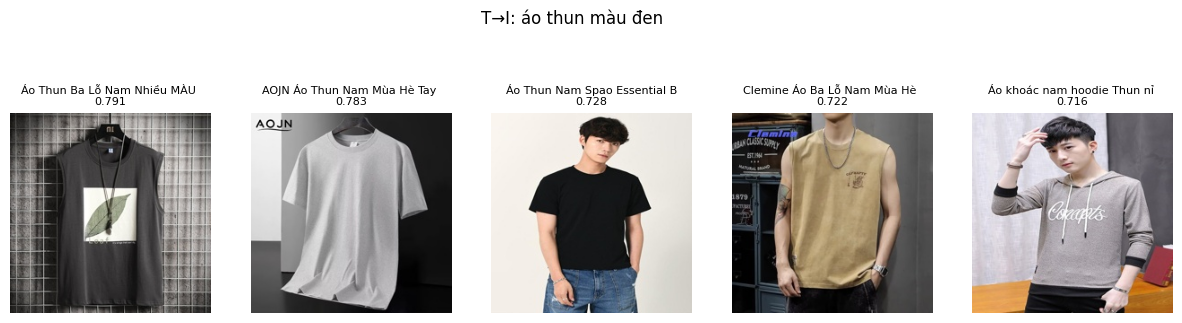

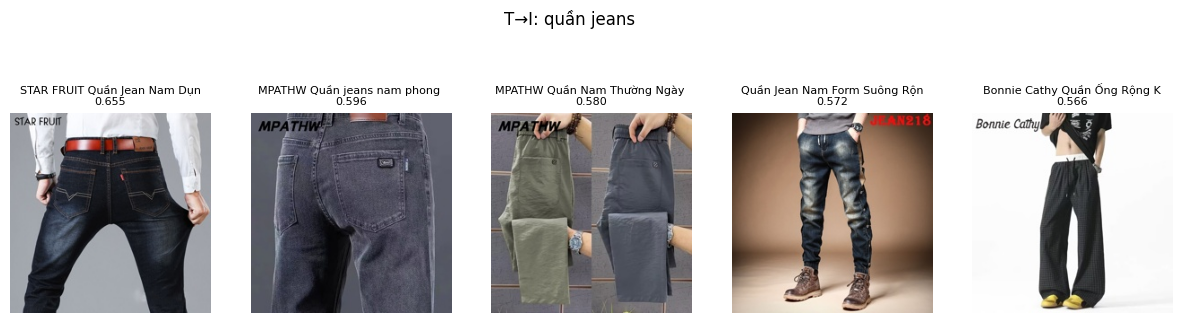

In [15]:
#text to image
def show(idxs, title, scores=None):
    fig, axs = plt.subplots(1, len(idxs), figsize=(3 * len(idxs), 4.2))
    if len(idxs) == 1: axs = [axs]
    for n, (ax, i) in enumerate(zip(axs, idxs)):
        ax.imshow(Image.open(g_paths[i])); ax.axis('off')
        t = g_meta[i]['name'][:28]
        if scores is not None: t += f'\n{scores[n]:.3f}'
        ax.set_title(t, fontsize=8)
    fig.suptitle(title); plt.show()

def search_text(query, k=5):
    sims = (embed_texts([query]) @ gallery.T)[0]
    top = sims.topk(k)
    show(top.indices.tolist(), f'T→I: {query}', top.values.tolist())

search_text('áo thun màu đen')
search_text('quần jeans ')

In [16]:
def search_image(img_path, k=5):
    q = embed_images([Path(img_path)])
    top = (q @ gallery.T)[0].topk(k)
    plt.figure(figsize=(3, 4)); plt.imshow(Image.open(img_path)); plt.axis('off'); plt.title('Query'); plt.show()
    show(top.indices.tolist(), 'I→I kết quả', top.values.tolist())

# Ảnh có sẵn trong gallery (kết quả đầu tiên sẽ là chính nó):
#search_image(g_paths[0])
search_image('/content/2.webp')

encode ảnh:   0%|          | 0/1 [00:00<?, ?it/s]


FileNotFoundError: [Errno 2] No such file or directory: '/content/2.webp'